# 6. Video CNN R(2+1)D + SVM

Tretí model: príznaky z video siete R(2+1)D (notebook 3), ktorá spracúva priestor aj čas,
a nad nimi rovnaký SVM a rovnaký protokol hodnotenia ako v notebooku 4.
Rozdiel oproti CNN-SVM je teda iba v tom, odkiaľ pochádzajú príznaky.

In [1]:
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

from har_utils import CLASSES, evaluate_svm, summarize, svm_search

df = pd.read_csv("index.csv")
X = np.load("features_r21d.npy")           # (klipy, 512)
print(X.shape)

(238, 512)


In [2]:
results, y_all, p_all = evaluate_svm(X, df)

Path("results").mkdir(exist_ok=True)
results.to_csv("results/video_cnn_svm.csv", index=False)
print(summarize(results, "R(2+1)D + SVM").to_string())

                                  acc        bal_acc             f1
model         test_set                                             
R(2+1)D + SVM hmdb      0.940 ± 0.031  0.947 ± 0.025  0.938 ± 0.032


              precision    recall  f1-score   support

         eat       0.88      0.98      0.93       332
        clap       0.99      0.90      0.94       444

    accuracy                           0.94       776
   macro avg       0.94      0.94      0.94       776
weighted avg       0.94      0.94      0.94       776



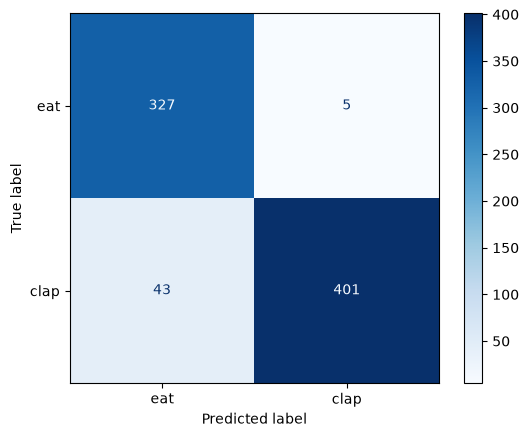

In [3]:
print(classification_report(y_all, p_all, target_names=CLASSES))
ConfusionMatrixDisplay.from_predictions(y_all, p_all, display_labels=CLASSES, cmap="Blues");

## Finálny model pre kameru

Po vyhodnotení natrénujeme SVM na **všetkých** klipoch (hyperparametre opäť vyberie
krížová validácia) a uložíme ho. Tento model používa skript `08_camera.py`.

In [4]:
gs = svm_search(X, df.label.values, df.source.values)
print("vybrané parametre:", gs.best_params_)

Path("models").mkdir(exist_ok=True)
joblib.dump(gs.best_estimator_, "models/svm_r21d.joblib")

vybrané parametre: {'clf__C': 0.01, 'clf__kernel': 'linear'}


['models/svm_r21d.joblib']